# Case Study 3: Logistic Regression on the Titanic Dataset

**Fundamentals of Data Science**

**Student:** V. Sai Eshwar  
**Roll No.:** 160124733205  
**Section:** CSE-3  
**Year:** 3rd Year  
**Faculty:** Smt. S. Durga Devi

## 1. Problem statement
Build and evaluate a logistic regression classifier that predicts whether a Titanic passenger survived (`Survived = 1`) or did not survive (`Survived = 0`) from selected passenger attributes. This is a supervised binary-classification task.

## 2. Methodology
1. Load the CSV and inspect its shape, columns, data types, summary statistics, and missing values.
2. Explore survival counts and relationships with sex, passenger class, age, and numeric variables.
3. Use a reproducible stratified 80/20 train-test split.
4. Impute missing numerical values with the training-set median, scale numerical features, impute categorical values with the most frequent category, and one-hot encode categories. All preprocessing is fitted inside a scikit-learn pipeline to reduce data leakage.
5. Train logistic regression and evaluate it using accuracy, precision, recall, F1-score, ROC-AUC, a confusion matrix, and ROC curve.
6. Interpret coefficients as effects on log-odds, not as guaranteed causal effects.

**Feature selection note:** `PassengerId`, `Name`, `Ticket`, and `Cabin` are excluded from the baseline model. IDs are not meaningful predictors, names/tickets have many unique values, and cabin is highly incomplete. The model uses `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked`.

## 3. Import libraries

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving titanic.csv to titanic.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 4. Load and inspect the dataset
The following cells check that the expected file is available and reveal the data structure before modeling.

In [ ]:
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.rename("data_type").to_frame())
display(df.describe(include="all").T)

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,data_type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "Missing values": missing,
    "Missing percentage": (missing / len(df) * 100).round(2)
})
display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())
print("Target counts:\n", df["Survived"].value_counts().sort_index())
print("Target proportions:\n", df["Survived"].value_counts(normalize=True).sort_index().round(3))

,Missing values,Missing percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Duplicate rows: 0
Target counts:
 Survived
0    549
1    342
Name: count, dtype: int64
Target proportions:
 Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


### Initial observations
This CSV contains 891 rows and 12 columns. `Age` has 177 missing values, `Cabin` has 687 missing values, and `Embarked` has 2 missing values. The target `Survived` has no missing values. There are 549 non-survivors and 342 survivors, so the classes are not perfectly balanced. The preprocessing pipeline below handles missing values in selected predictors without dropping most rows.

## 5. Exploratory data analysis (EDA)

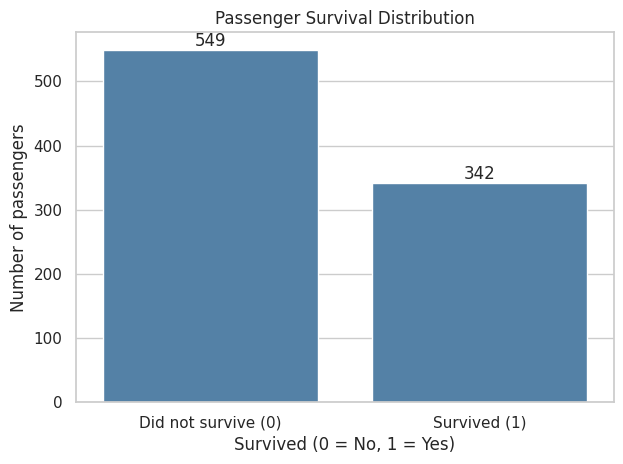

In [ ]:
# Survival distribution: labels explain the binary target.
ax = sns.countplot(data=df, x="Survived", color="steelblue")
ax.set_title("Passenger Survival Distribution")
ax.set_xlabel("Survived (0 = No, 1 = Yes)")
ax.set_ylabel("Number of passengers")
ax.set_xticks([0, 1], ["Did not survive (0)", "Survived (1)"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Interpretation:** There are 549 non-survivors and 342 survivors in the dataset. A classifier that always predicts the majority class would already be correct for about 61.6% of rows, so accuracy must be considered alongside recall, F1-score, and ROC-AUC.

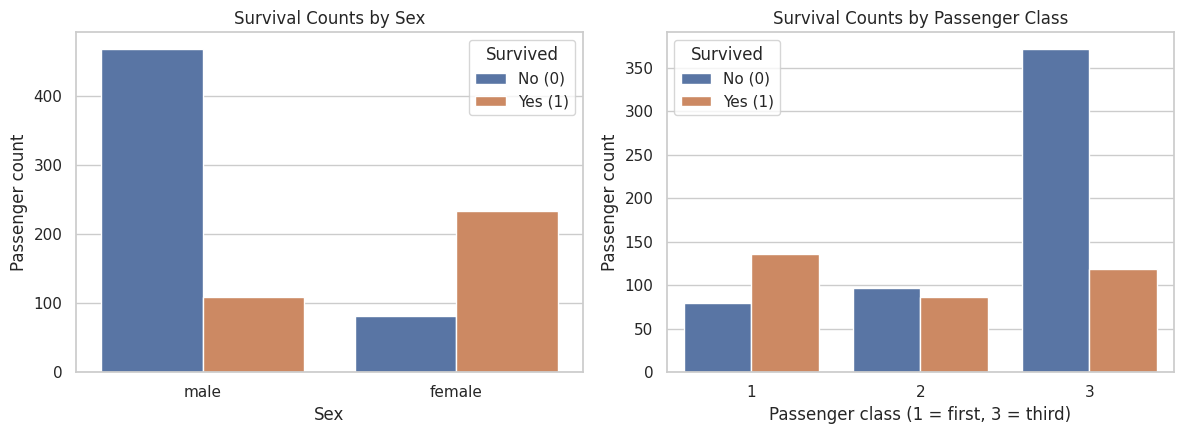

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[0], palette="deep")
axes[0].set_title("Survival Counts by Sex"); axes[0].set_xlabel("Sex"); axes[0].set_ylabel("Passenger count")
axes[0].legend(title="Survived", labels=["No (0)", "Yes (1)"])
sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[1], palette="deep")
axes[1].set_title("Survival Counts by Passenger Class"); axes[1].set_xlabel("Passenger class (1 = first, 3 = third)"); axes[1].set_ylabel("Passenger count")
axes[1].legend(title="Survived", labels=["No (0)", "Yes (1)"])
plt.tight_layout(); plt.show()

**Interpretation:** In this dataset, survival counts differ substantially by sex and passenger class. Women have more recorded survivors relative to their total than men, and first-class passengers show a different survival pattern from third-class passengers. These are descriptive patterns, not proof that any one attribute caused survival.

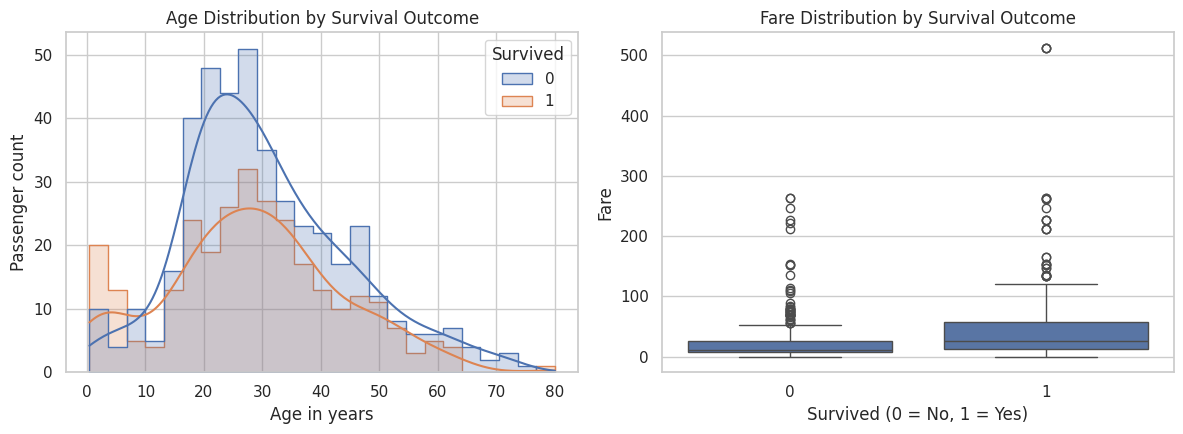

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, kde=True, element="step",
             stat="count", common_norm=False, ax=axes[0])
axes[0].set_title("Age Distribution by Survival Outcome"); axes[0].set_xlabel("Age in years"); axes[0].set_ylabel("Passenger count")
sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1])
axes[1].set_title("Fare Distribution by Survival Outcome"); axes[1].set_xlabel("Survived (0 = No, 1 = Yes)"); axes[1].set_ylabel("Fare")
plt.tight_layout(); plt.show()

**Interpretation:** Age distributions overlap between outcome groups, and fare values are right-skewed with some high-fare observations. The box plot can reveal differences in fare distributions, but outliers and overlapping distributions mean fare alone cannot determine an individual outcome.

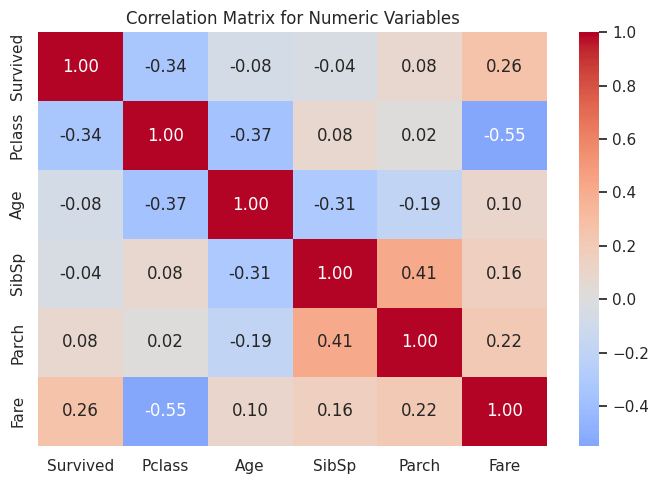

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000,-0.338,-0.077,-0.035,0.082,0.257
Pclass,-0.338,1.000,-0.369,0.083,0.018,-0.549
Age,-0.077,-0.369,1.000,-0.308,-0.189,0.096
SibSp,-0.035,0.083,-0.308,1.000,0.415,0.160
Parch,0.082,0.018,-0.189,0.415,1.000,0.216
Fare,0.257,-0.549,0.096,0.160,0.216,1.000


In [ ]:
numeric_for_corr = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
correlation = df[numeric_for_corr].corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix for Numeric Variables")
plt.tight_layout(); plt.show()
display(correlation.round(3))

**Interpretation:** Correlation values summarize linear association between numeric columns. The correlation matrix is exploratory only: it does not show nonlinear relationships and does not establish causation. `Pclass` is coded numerically, so its correlation should be interpreted with the coding in mind.

## 6. Data preprocessing and train-test split

In [ ]:
target = "Survived"
feature_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[feature_columns].copy()
y = df[target].copy()

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training survival rate:", round(y_train.mean(), 3))
print("Testing survival rate:", round(y_test.mean(), 3))

Training rows: 712
Testing rows: 179
Training survival rate: 0.383
Testing survival rate: 0.385


We use a stratified split so the training and testing sets retain similar survival proportions. Numeric columns are median-imputed and standardized. Categorical columns are filled using the most frequent training value and one-hot encoded. Putting transformations in a pipeline means they are learned from training data only, then applied to the test data.

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 7. Model evaluation

In [ ]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}
metrics_df = pd.DataFrame({"Metric": metrics.keys(), "Score": metrics.values()})
display(metrics_df.style.format({"Score": "{:.4f}"}))
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

,Metric,Score
0,Accuracy,0.8045
1,Precision,0.7931
2,Recall,0.6667
3,F1-score,0.7244
4,ROC-AUC,0.8437


                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



**How to read the metrics:** Accuracy is the fraction of all test cases classified correctly. Precision measures how many predicted survivors actually survived. Recall measures how many actual survivors were identified. F1-score balances precision and recall. ROC-AUC measures how well the model ranks survivors above non-survivors across probability thresholds. Values shown are calculated from this notebook's held-out test set, not copied from an example.

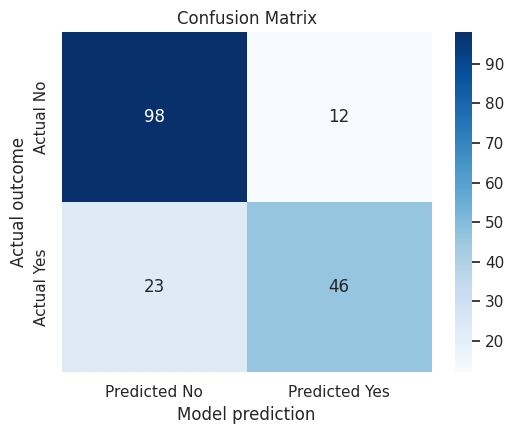

Confusion matrix order: [[true negatives, false positives], [false negatives, true positives]]


In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix")
plt.xlabel("Model prediction"); plt.ylabel("Actual outcome")
plt.tight_layout(); plt.show()
print("Confusion matrix order: [[true negatives, false positives], [false negatives, true positives]]")

**Interpretation:** The top-left and bottom-right cells are correct predictions. The top-right cell represents passengers predicted to survive who did not survive, while the bottom-left cell represents actual survivors missed by the model. Review these counts together with precision and recall.

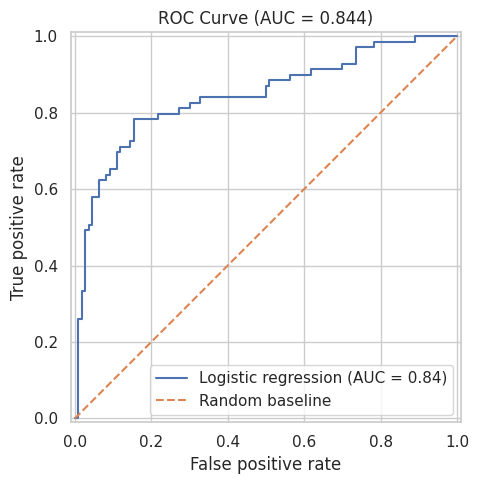

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_probability, ax=ax, name="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title(f"ROC Curve (AUC = {metrics['ROC-AUC']:.3f})")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation:** The ROC curve plots true-positive rate against false-positive rate at different thresholds. A curve closer to the upper-left corner generally indicates better separation. The ROC-AUC printed in the legend summarizes ranking performance; it does not mean the model is that percentage accurate.

## 8. Coefficient interpretation

In [ ]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds ratio (exp coefficient)": np.exp(coefficients)
}).sort_values("Coefficient", ascending=False)
display(coefficient_table.round(3))

,Feature,Coefficient,Odds ratio (exp coefficient)
5,cat__Sex_female,1.299,3.667
8,cat__Embarked_Q,0.305,1.356
4,num__Fare,0.100,1.105
7,cat__Embarked_C,0.032,1.033
3,num__Parch,-0.066,0.936
2,num__SibSp,-0.261,0.771
9,cat__Embarked_S,-0.358,0.699
1,num__Age,-0.503,0.605
0,num__Pclass,-0.922,0.398
6,cat__Sex_male,-1.321,0.267


**Interpretation guidance:** A positive coefficient increases the model's predicted log-odds of survival, while a negative coefficient decreases them, holding the other included variables constant. For a one-unit increase in a numeric feature, the odds multiplier is `exp(coefficient)`; because numeric features are standardized, one unit corresponds to one standard deviation for those columns. One-hot encoded coefficients are relative to the category omitted as the reference level. Coefficients are model associations and should not be interpreted as causal effects.

## 9. Conclusion

This case study built a logistic regression classifier to predict Titanic survival using passenger class, sex, age, family counts, fare, and embarkation port. Missing values and categorical variables were handled in a preprocessing pipeline, and the data was split into training and testing subsets with stratification. On the held-out test set, the model achieved accuracy **0.804**, precision **0.793**, recall **0.667**, F1-score **0.724**, and ROC-AUC **0.844**.

The exploratory plots indicate differences in survival patterns by sex and passenger class. Model performance is useful for an educational baseline, but it is limited by the selected features, the single train-test split, historical dataset biases, and the fact that predictions are probabilistic rather than certain. A future extension could compare cross-validation, tune regularization, and compare with other classifiers.

## 10. Optional extension: save the model for Streamlit

In [ ]:
# Run this cell if you want to create the model file used by app.py.
# Requires joblib: pip install joblib
import joblib
joblib.dump(model, "titanic_logistic_model.joblib")
print("Saved titanic_logistic_model.joblib")

Saved titanic_logistic_model.joblib


## References and attribution
- Dataset: the `titanic.csv` file supplied for this assignment.
- Libraries: pandas, NumPy, Matplotlib, Seaborn, and scikit-learn documentation.
- This notebook is a worked study scaffold. The student should run every cell, inspect the outputs, and make sure they can explain each preprocessing choice, graph, metric, and coefficient before submission.